In [2]:
# load a matrix from a space-separated file and show it as an image
import sys
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/')
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import os
from stat_utils import bic_gaussian_from_rmse
from model_utils import force_model_params, migrate_output_scale_to_input_scale_state_dict

In [3]:


def compute_k_params(model_state_dict, 
                     exclude_by_startwith=['_'], 
                     exclude_by_name=['sigma_x'], 
                     count_for_one={'sigma_b', 'direct_injection_scale','output_scale','u_feedback_scale', 
                                    'x_slow_alpha', 'x_fast_gain', 'x_fast_alpha'}):
    k_params = 0
    for key in model_state_dict:
        if any([key.startswith(excl) for excl in exclude_by_startwith]):
            continue
        if key in exclude_by_name:
            continue
        param_tensor = model_state_dict[key]
        this_param_size = param_tensor.shape[-1] if key not in count_for_one else 1
        print(f'param: {key}, size: {this_param_size}')
        k_params += this_param_size
    return k_params

def read_rmse_and_bic_from_path(bic_path,seeds):
    model_state_dict = torch.load(os.path.join(bic_path, 'model_state_dict.pt'), map_location='cpu')
    k_params = compute_k_params(model_state_dict)
    print(f'detected k_params: {k_params}')
    a_exp = np.loadtxt(os.path.join(bic_path, 'a_exp.txt'))
    a_pred = np.loadtxt(os.path.join(bic_path, 'a_pred.txt'))

    subjs = a_exp.shape[1] // seeds
    print(f'detected subjs: {subjs}')

    rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])
    n_samples = np.sum(~np.isnan(a_exp),axis=0).reshape([subjs, seeds])
    assert np.all(n_samples == n_samples[:, [0]])
    n_samples = n_samples[:, 0]

    best_seed_idx = np.nanargmin(rmse, axis=1)
    best_rmse = rmse[np.arange(subjs), best_seed_idx]
    best_bics = [bic_gaussian_from_rmse(this_rmse, n=this_n, k=k_params) for this_rmse, this_n in zip(best_rmse, n_samples)]
    return {"best_rmse": np.array(best_rmse), "best_bics": np.array(best_bics)}


# default seed count
# seeds = 128//2 # 128*2#*2 # 18#72#18 #128
#



# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LernerWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1/'

# lerner_dual_rate_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/', seeds=128)


# 

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_g1_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRmin/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LernerWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1/'


In [4]:
rcConf = {
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
}
# ufigx,ufigy = (8.5 / 2, 4.2 / 1.5)
ufigx,ufigy = (7.5 / 2, 4.2 / 1.5)

/tmp/ipykernel_4058156/955964150.py:64: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2, axis=0)).reshape(subjs, seeds_for_compare)
/scratch/ar2342/miconda3/envs/py_frogs/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


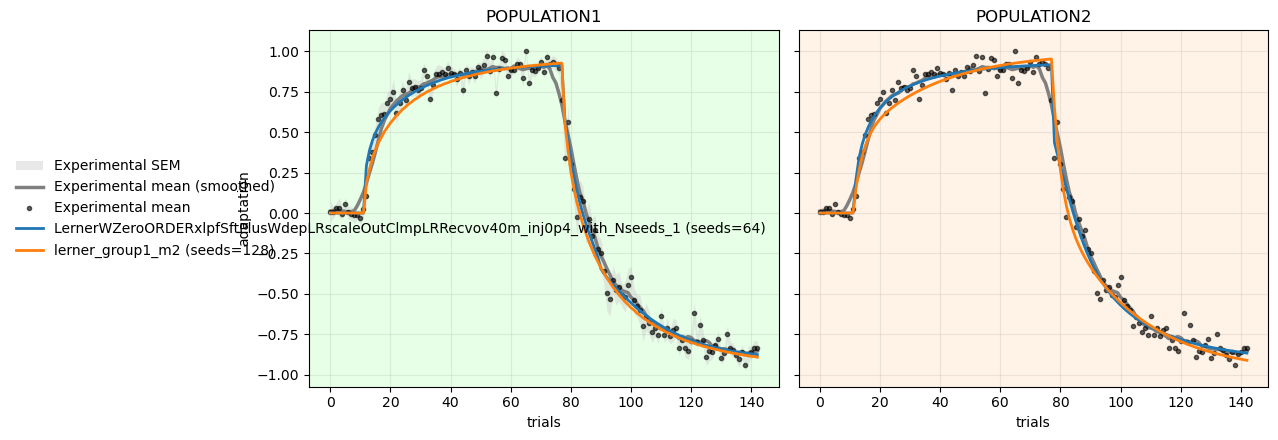

In [5]:
# Compare two result folders via best-MSE fits, averaged over POPULATION1 and POPULATION2 participants separately.
# result_path_a = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
result_path_a = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LernerWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1/'; seeds=128//2
# result_path_a = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path_a = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
result_path_b = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/'
split_idx = 15  # first 15 participants are individuals; the remaining is the average

# Set these explicitly when known. If one is left as None, it can be inferred from the other path's subject count.
seeds_a = seeds
seeds_b = None

def moving_average(x, window=9):
    x = np.asarray(x, dtype=float)
    window = max(1, int(window))
    if window == 1:
        return x.copy()

    pad_left = window // 2
    pad_right = window - 1 - pad_left
    x_pad = np.pad(x, (pad_left, pad_right), mode='edge')

    valid = np.isfinite(x_pad).astype(float)
    x_filled = np.where(np.isfinite(x_pad), x_pad, 0.0)
    kernel = np.ones(window, dtype=float)

    numer = np.convolve(x_filled, kernel, mode='valid')
    denom = np.convolve(valid, kernel, mode='valid')

    out = np.full_like(numer, np.nan, dtype=float)
    np.divide(numer, denom, out=out, where=denom > 0)
    return out

def load_best_fit_summary(result_path, split_idx=8, seeds_for_compare=None, expected_subjs=None):
    a_exp = np.loadtxt(os.path.join(result_path, 'a_exp.txt'))
    a_pred = np.loadtxt(os.path.join(result_path, 'a_pred.txt'))

    if a_exp.shape != a_pred.shape:
        raise ValueError(f'Shape mismatch in {result_path}: a_exp {a_exp.shape} vs a_pred {a_pred.shape}')

    n_cols = a_exp.shape[1]
    if seeds_for_compare is None:
        if expected_subjs is None:
            raise ValueError(
                'Need either seeds_for_compare or expected_subjs to determine the seed count for '
                f'{result_path}'
            )
        if n_cols % expected_subjs != 0:
            raise ValueError(
                f'Number of columns ({n_cols}) in {result_path} is not divisible by expected_subjs={expected_subjs}'
            )
        subjs = expected_subjs
        seeds_for_compare = n_cols // subjs
    else:
        if n_cols % seeds_for_compare != 0:
            raise ValueError(
                f'Number of columns ({n_cols}) in {result_path} is not divisible by seeds={seeds_for_compare}'
            )
        subjs = n_cols // seeds_for_compare

    if split_idx <= 0 or split_idx >= subjs:
        raise ValueError(f'Invalid split_idx={split_idx} for subjs={subjs}')

    rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2, axis=0)).reshape(subjs, seeds_for_compare)
    best_seed_idx = np.nanargmin(rmse, axis=1)
    best_exp = np.full((a_exp.shape[0], subjs), np.nan)
    best_pred = np.full((a_pred.shape[0], subjs), np.nan)

    for subj in range(subjs):
        col_idx = subj * seeds_for_compare + best_seed_idx[subj]
        this_exp = a_exp[:, col_idx].copy()
        this_pred = a_pred[:, col_idx].copy()
        polarity = np.sign(np.nanmean(this_exp[:175]))
        if not np.isfinite(polarity) or polarity == 0:
            polarity = 1.0
        best_exp[:, subj] = polarity * this_exp
        best_pred[:, subj] = polarity * this_pred

    return {
        'result_path': result_path,
        'subjs': subjs,
        'seeds_for_compare': seeds_for_compare,
        'best_seed_idx': best_seed_idx,
        'best_exp': best_exp,
        'best_pred': best_pred,
        'mean_exp_pop1': np.nanmean(best_exp[:, :split_idx], axis=1),
        'mean_exp_pop2': np.nanmean(best_exp[:, split_idx:], axis=1),
        'mean_pred_pop1': np.nanmean(best_pred[:, :split_idx], axis=1),
        'mean_pred_pop2': np.nanmean(best_pred[:, split_idx:], axis=1),
    }

summary_a = load_best_fit_summary(
    result_path_a,
    split_idx=split_idx,
    seeds_for_compare=seeds_a,
)
summary_b = load_best_fit_summary(
    result_path_b,
    split_idx=split_idx,
    seeds_for_compare=seeds_b,
    expected_subjs=summary_a['subjs'],
)

if summary_a['subjs'] != summary_b['subjs']:
    raise ValueError(f"Subject count mismatch: {summary_a['subjs']} vs {summary_b['subjs']}")
if not np.allclose(summary_a['mean_exp_pop1'], summary_b['mean_exp_pop1'], equal_nan=True):
    raise ValueError('Averaged POPULATION1 experimental data differs between the two result paths.')
if not np.allclose(summary_a['mean_exp_pop2'], summary_b['mean_exp_pop2'], equal_nan=True):
    raise ValueError('Averaged POPULATION2 experimental data differs between the two result paths.')

label_a = os.path.basename(os.path.normpath(result_path_a)) or result_path_a
label_b = os.path.basename(os.path.normpath(result_path_b)) or result_path_b
trial_idx = np.arange(summary_a['mean_exp_pop1'].shape[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
group_specs = [
    ('POPULATION1', 'mean_exp_pop1', 'mean_pred_pop1', (0.90, 1.00, 0.90), summary_a['best_exp'][:, :split_idx]),
    ('POPULATION2', 'mean_exp_pop2', 'mean_pred_pop2', (1.00, 0.95, 0.90), summary_a['best_exp'][:, split_idx:]),
]

for ax, (group_name, exp_key, pred_key, facecolor, exp_mat) in zip(axes, group_specs):
    ax.set_facecolor(facecolor)

    exp_mean = summary_a[exp_key]
    exp_n = np.sum(~np.isnan(exp_mat), axis=1)
    exp_sem = np.divide(
        np.nanstd(exp_mat, axis=1, ddof=1),
        np.sqrt(exp_n),
        out=np.zeros_like(exp_mean, dtype=float),
        where=exp_n > 1,
    )
    exp_mean_smooth = moving_average(exp_mean, window=10)

    ax.fill_between(
        trial_idx,
        exp_mean - exp_sem,
        exp_mean + exp_sem,
        color='lightgray',
        alpha=0.5,
        linewidth=0,
        label='Experimental SEM',
    )
    ax.plot(trial_idx, exp_mean_smooth, color='gray', linewidth=2.5, label='Experimental mean (smoothed)')
    ax.plot(trial_idx, exp_mean, '.', color='black', alpha=0.6, label='Experimental mean')

    ax.plot(
        trial_idx,
        summary_a[pred_key],
        color='tab:blue',
        linewidth=2,
        label=f'{label_a} (seeds={summary_a["seeds_for_compare"]})',
    )
    ax.plot(
        trial_idx,
        summary_b[pred_key],
        color='tab:orange',
        linewidth=2,
        label=f'{label_b} (seeds={summary_b["seeds_for_compare"]})',
    )
    ax.set_title(group_name)
    ax.set_xlabel('trials')
    ax.grid(alpha=0.25)

axes[0].set_ylabel('adaptation')
axes[0].legend(frameon=False)
# plt.suptitle('Best-MSE fit means by participant group')
plt.tight_layout()


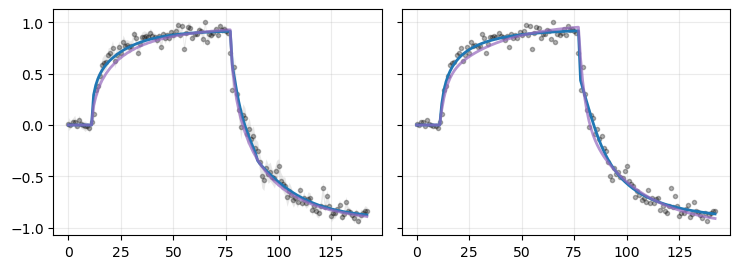

In [16]:
# Alternative experimental averaging: enforce equal non-NaN counts per trace,
# then average y and x over non-NaN entry index.


save_path = '/homes/ar2342/one_more_dir/contextual_frogs/gnu_fig_data/lerner/'
nickname_a = 'CLNN'
nickname_b = 'dual-rate'



def strict_nonan_average_with_sem(exp_mat, x_full):
    exp_mat = np.asarray(exp_mat, dtype=float)
    x_full = np.asarray(x_full, dtype=float)

    if exp_mat.ndim != 2:
        raise ValueError(f'exp_mat must be 2D, got shape {exp_mat.shape}')

    # 1) same number of non-NaNs in each trace (column)
    nn_counts = np.sum(~np.isnan(exp_mat), axis=0)
    if not np.all(nn_counts == nn_counts[0]):
        raise ValueError(f'Non-NaN counts differ across traces: {nn_counts}')

    k = int(nn_counts[0])
    if k == 0:
        raise ValueError('All experimental traces are fully NaN.')

    n_traces = exp_mat.shape[1]
    y_stack = np.empty((k, n_traces), dtype=float)
    x_stack = np.empty((k, n_traces), dtype=float)

    # 2) drop NaNs per trace; average by non-NaN entry index
    for j in range(n_traces):
        mask = ~np.isnan(exp_mat[:, j])
        y_valid = exp_mat[mask, j]
        x_valid = x_full[mask]
        if y_valid.shape[0] != k:
            raise ValueError('Internal consistency error after non-NaN count check.')
        y_stack[:, j] = y_valid
        x_stack[:, j] = x_valid

    x_mean = np.mean(x_stack, axis=1)
    y_mean = np.mean(y_stack, axis=1)

    sem = np.zeros(k, dtype=float)
    if n_traces > 1:
        sem = np.std(y_stack, axis=1, ddof=1) / np.sqrt(n_traces)

    return x_mean, y_mean, sem


fig, axes = plt.subplots(1, 2, figsize=(ufigx*2, ufigy), sharey=True)
group_specs = [
    ('POPULATION1', 'mean_pred_pop1', (0.90, 1.00, 0.90), summary_a['best_exp'][:, :split_idx], 'per_subject'),
    ('POPULATION2', 'mean_pred_pop2', (1.00, 0.95, 0.90), summary_a['best_exp'][:, split_idx:], 'mean_subjects'),
]

for ax, (group_name, pred_key, facecolor, exp_mat, avg_type) in zip(axes, group_specs):
    # ax.set_facecolor(facecolor)

    x_exp, y_exp, y_sem = strict_nonan_average_with_sem(exp_mat, trial_idx)
    y_exp_smooth = moving_average(y_exp, window=10)

    ax.fill_between(
        x_exp,
        y_exp - y_sem,
        y_exp + y_sem,
        color='lightgray',
        alpha=0.5,
        linewidth=0,
        label='Experimental SEM (non-NaN aligned)',
    )
    # ax.plot(x_exp, y_exp_smooth, color='gray', linewidth=2.5, label='Experimental mean (smoothed, non-NaN aligned)')
    ax.plot(x_exp, y_exp, '.', color='black', alpha=0.3, label='Experimental mean (non-NaN aligned)')

    ax.plot(
        trial_idx,
        summary_a[pred_key],
        color='tab:blue',
        linewidth=2,
        label=f'{label_a} (seeds={summary_a["seeds_for_compare"]})',
    )
    ax.plot(
        trial_idx,
        summary_b[pred_key],
        color='tab:purple',
        linewidth=2, alpha = 0.7,
        label=f'{label_b} (seeds={summary_b["seeds_for_compare"]})',
    )


    ax.grid(alpha=0.25)


    np.savetxt(
        os.path.join(save_path, f'experiment_xysem_{avg_type}.txt'),
        np.stack((x_exp, y_exp, y_sem), axis=1),
        fmt='%.6f',
    )
    for this_summary, this_nickname in zip([summary_a, summary_b], [nickname_a, nickname_b]):
        np.savetxt(
            os.path.join(save_path, f'predictions_{this_nickname}_{avg_type}.txt'),
            np.stack((trial_idx, this_summary[pred_key]), axis=1),
            fmt='%.6f',
        )

plt.tight_layout()


In [7]:
exp_mat.shape

(143, 1)

In [8]:
runs = ['/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/',
        f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LERNERployWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1',
        f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LERNERploy2WZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1',
        '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LernerWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1/']
seeds = [128, 128//2, 128//2, 128//2]


In [9]:
bics = [read_rmse_and_bic_from_path(run, seeds=seed)['best_bics'] for run, seed in zip(runs, seeds)]

param: log_learning_rate, size: 2
param: sp_weight_decay, size: 2
detected k_params: 4
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16


/tmp/ipykernel_4058156/976065542.py:28: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])


In [10]:
bics

[array([ -99.87584912,  -84.96303609, -179.7240424 ,   89.16490034,
         -87.50594039,  -94.95833248, -155.24018943,  -91.33946421,
         -38.23495616,   91.59617519,   -7.13483915,  -64.38430068,
          32.28714677, -157.76668838,  -37.91011172, -308.51504278]),
 array([-108.96001811, -128.87730934, -172.72764064,   97.57514295,
         -89.3969856 ,  -89.5759039 , -170.26274299,  -96.16423024,
         -85.4785856 ,   87.47403898,  -24.17172458,  -70.27537105,
          33.671113  , -146.5996129 ,  -40.45863753, -343.37090481]),
 array([-117.23436638, -129.2837382 , -170.76400444,   95.51703414,
         -89.33552941,  -91.46961591, -175.35629208,  -96.14087982,
         -81.78310259,   73.95308545,  -27.52133614,  -74.4246858 ,
          28.26715589, -146.51428688,  -44.3455825 , -368.62002818]),
 array([-115.91611855, -129.04163445, -171.98350119,   94.47247572,
         -91.47017384,  -90.61289933, -172.99964927,  -97.7345052 ,
         -77.66354356,   73.02056492,  -33

In [18]:
bics = np.stack(bics)
np.savetxt(
    os.path.join(save_path, f'bics_per_subjects_dual_rate_clnnPoly1Poly2Exp.txt'),
    bics.T,
    fmt='%.6f',
)

In [15]:
print(f'sum of  BIC  (per subjects) [dual rate, CLNN: poly1, poly2, exp]: {bics[:,:-1].sum(axis=1)},\n  BIC of the mean fit: {bics[:,-1]}')

sum of  BIC  (per subjects) [dual rate, CLNN: poly1, poly2, exp]: [ -885.98952791 -1004.22846755 -1046.43614466 -1049.47796902],
  BIC of the mean fit: [-308.51504278 -343.37090481 -368.62002818 -366.72299209]


In [13]:
bics

array([[ -99.87584912,  -84.96303609, -179.7240424 ,   89.16490034,
         -87.50594039,  -94.95833248, -155.24018943,  -91.33946421,
         -38.23495616,   91.59617519,   -7.13483915,  -64.38430068,
          32.28714677, -157.76668838,  -37.91011172, -308.51504278],
       [-108.96001811, -128.87730934, -172.72764064,   97.57514295,
         -89.3969856 ,  -89.5759039 , -170.26274299,  -96.16423024,
         -85.4785856 ,   87.47403898,  -24.17172458,  -70.27537105,
          33.671113  , -146.5996129 ,  -40.45863753, -343.37090481],
       [-117.23436638, -129.2837382 , -170.76400444,   95.51703414,
         -89.33552941,  -91.46961591, -175.35629208,  -96.14087982,
         -81.78310259,   73.95308545,  -27.52133614,  -74.4246858 ,
          28.26715589, -146.51428688,  -44.3455825 , -368.62002818],
       [-115.91611855, -129.04163445, -171.98350119,   94.47247572,
         -91.47017384,  -90.61289933, -172.99964927,  -97.7345052 ,
         -77.66354356,   73.02056492,  -33.54

In [19]:
bics.T

array([[ -99.87584912, -108.96001811, -117.23436638, -115.91611855],
       [ -84.96303609, -128.87730934, -129.2837382 , -129.04163445],
       [-179.7240424 , -172.72764064, -170.76400444, -171.98350119],
       [  89.16490034,   97.57514295,   95.51703414,   94.47247572],
       [ -87.50594039,  -89.3969856 ,  -89.33552941,  -91.47017384],
       [ -94.95833248,  -89.5759039 ,  -91.46961591,  -90.61289933],
       [-155.24018943, -170.26274299, -175.35629208, -172.99964927],
       [ -91.33946421,  -96.16423024,  -96.14087982,  -97.7345052 ],
       [ -38.23495616,  -85.4785856 ,  -81.78310259,  -77.66354356],
       [  91.59617519,   87.47403898,   73.95308545,   73.02056492],
       [  -7.13483915,  -24.17172458,  -27.52133614,  -33.54908236],
       [ -64.38430068,  -70.27537105,  -74.4246858 ,  -73.74160197],
       [  32.28714677,   33.671113  ,   28.26715589,   27.86343009],
       [-157.76668838, -146.5996129 , -146.51428688, -146.56120637],
       [ -37.91011172,  -40.458637

<StemContainer object of 3 artists>

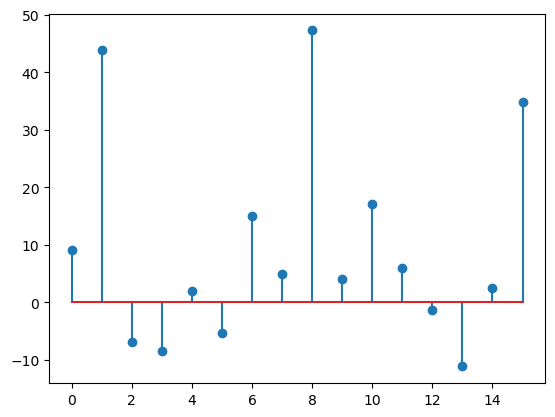

In [20]:
plt.stem(bics[0]-bics[1])